In [5]:
from google.colab import files

uploaded = files.upload()

Saving Reviews.csv.zip to Reviews.csv.zip


In [6]:
# After running the cell above and uploading your file, use the following command to unzip it.
# Replace 'your_file.zip' with the actual name of your uploaded zip file.
!unzip Reviews.csv.zip

Archive:  Reviews.csv.zip
  inflating: Reviews.csv             


In [7]:
import pandas as pd

df = pd.read_csv("Reviews.csv")

df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [8]:
df.shape

(568454, 10)

In [9]:
df.columns

Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [11]:
def sentiment_label(score):
    if score <= 2:
        return "negative"
    elif score == 3:
        return "neutral"
    else:
        return "positive"

df["Sentiment"] = df["Score"].apply(sentiment_label)

In [12]:
df["Sentiment"].value_counts()

,count
Sentiment,
positive,443777
negative,82037
neutral,42640


In [13]:
df = df[df["Sentiment"] != "neutral"]

In [14]:
df["Sentiment"].value_counts()

,count
Sentiment,
positive,443777
negative,82037


In [15]:
df = df[["Text", "Sentiment"]]

In [16]:
df.head()

,Text,Sentiment
0,I have bought several of the Vitality canned d...,positive
1,Product arrived labeled as Jumbo Salted Peanut...,negative
2,This is a confection that has been around a fe...,positive
3,If you are looking for the secret ingredient i...,negative
4,Great taffy at a great price. There was a wid...,positive


In [17]:
df = df.sample(n=20000, random_state=42)

In [18]:
df.shape

(20000, 2)

In [19]:
df["Sentiment"].value_counts()

,count
Sentiment,
positive,16902
negative,3098


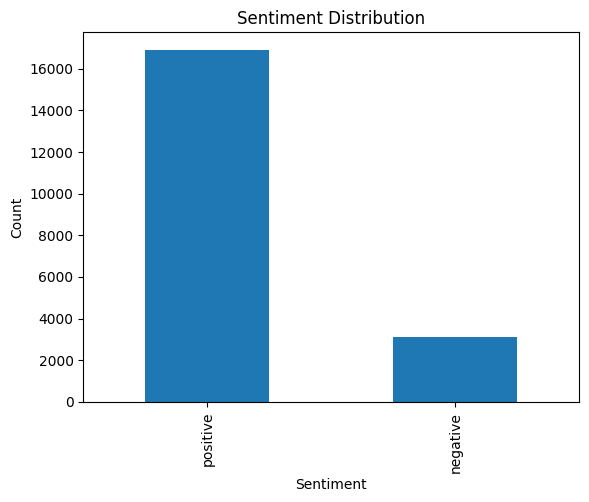

In [20]:
import matplotlib.pyplot as plt

df["Sentiment"].value_counts().plot(kind="bar")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

The dataset shows a clear imbalance between positive and negative reviews, with significantly more positive reviews. This suggests that customers are generally satisfied with the products. However, this imbalance may influence the model to favor predicting positive sentiment more frequently.

In [21]:
df["review_length"] = df["Text"].apply(lambda x: len(x.split()))

In [23]:
df["review_length"].describe()

,review_length
count,20000.000000
mean,77.744800
std,74.447496
min,8.000000
25%,33.000000
50%,55.000000
75%,95.000000
max,1853.000000


The analysis of review length shows that negative reviews tend to be slightly longer than positive reviews. This indicates that dissatisfied customers often provide more detailed explanations of their experiences, while satisfied customers tend to give shorter feedback.

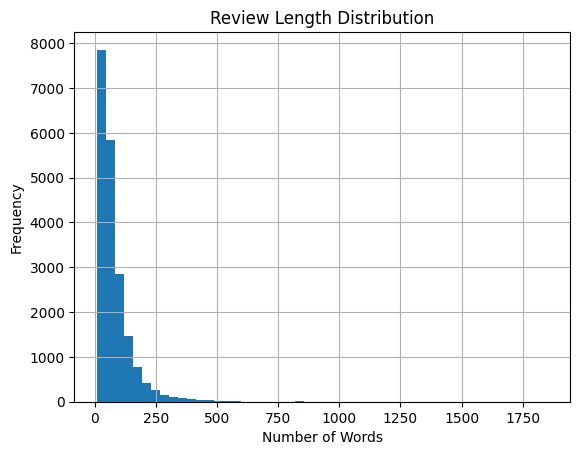

In [24]:
df["review_length"].hist(bins=50)
plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [25]:
df.sample(3)

,Text,Sentiment,review_length
46131,This was the worst loose tea I have ever had. ...,negative,25
198194,I really like the product.<br /><br />I have n...,positive,36
112690,i bought these on a warehouse deal and loved t...,positive,61


In [26]:
df["review_length"].mean()

np.float64(77.7448)

In [27]:
df.groupby("Sentiment")["review_length"].mean()

,review_length
Sentiment,
negative,85.584248
positive,76.307893


In [28]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["cleaned_text"] = df["Text"].apply(clean_text)

In [29]:
df[["Text", "cleaned_text"]].head()

,Text,cleaned_text
443593,This is a very high quality dog food with meat...,this is a very high quality dog food with meat...
136949,I love this cake mix and the other 3 mixes as ...,i love this cake mix and the other mixes as we...
520459,A nice strong brew. I am new to Keurig and hav...,a nice strong brew i am new to keurig and have...
219515,I just found PB2 and PB2 with chocolate and I ...,i just found pb and pb with chocolate and i am...
471273,Delightful mint tea as one would expect. Note ...,delightful mint tea as one would expect note t...


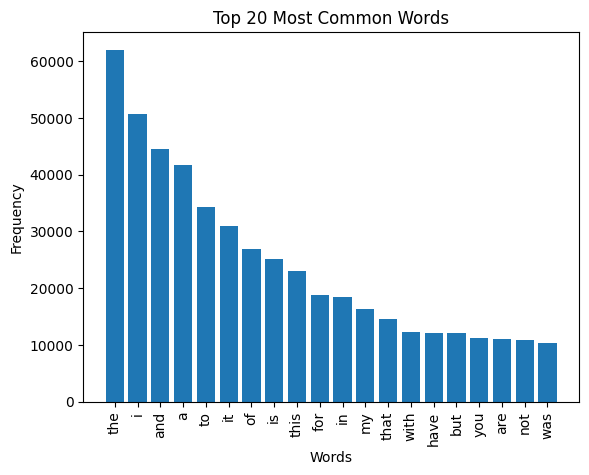

In [30]:
# Top 20 Most Common Words
# This visualization shows the most frequent words in the dataset, helping to understand common themes in the reviews.

from collections import Counter
import matplotlib.pyplot as plt

all_words = " ".join(df["cleaned_text"]).split()
common_words = Counter(all_words).most_common(20)

words = [w[0] for w in common_words]
counts = [w[1] for w in common_words]

plt.bar(words, counts)
plt.xticks(rotation=90)
plt.title("Top 20 Most Common Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

In [31]:
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


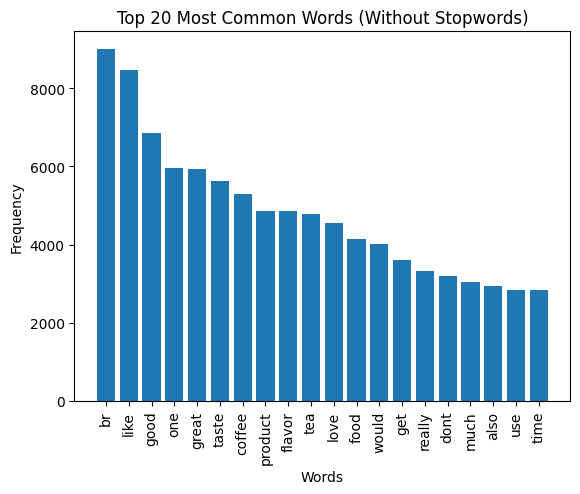

In [32]:
# Top 20 Most Common Words (Without stopwords)
# After removing common stopwords, the most frequent words provide more meaningful insights into the dataset.


from collections import Counter
import matplotlib.pyplot as plt

all_words = " ".join(df["cleaned_text"]).split()

# remove stopwords
filtered_words = [word for word in all_words if word not in stop_words]

common_words = Counter(filtered_words).most_common(20)

words = [w[0] for w in common_words]
counts = [w[1] for w in common_words]

plt.bar(words, counts)
plt.xticks(rotation=90)
plt.title("Top 20 Most Common Words (Without Stopwords)")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

After removing common stopwords, the most frequent words provide more meaningful insights into the dataset. Words related to product quality and user experience appear frequently, indicating that customers focus mainly on describing product performance and satisfaction.

In [33]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [34]:
tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(df["cleaned_text"])

In [35]:
sequences = tokenizer.texts_to_sequences(df["cleaned_text"])

In [36]:
max_length = 100
X = pad_sequences(sequences, maxlen=max_length)

In [37]:
import numpy as np

y = np.where(df["Sentiment"] == "positive", 1, 0)

In [38]:
print(X.shape)
print(y.shape)

(20000, 100)
(20000,)


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [41]:
print(X_train.shape, X_test.shape)

(16000, 100) (4000, 100)


In [43]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense

model = Sequential([
    Embedding(input_dim=10000, output_dim=64, input_length=100),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [44]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [50]:
import time

start = time.time()

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    validation_data=(X_test, y_test),
    batch_size=32
)

end = time.time()
print("Keras training time:", round(end - start, 2), "seconds")

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8516 - loss: 0.3903 - val_accuracy: 0.8637 - val_loss: 0.3088
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9024 - loss: 0.2430 - val_accuracy: 0.9057 - val_loss: 0.2333
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9308 - loss: 0.1780 - val_accuracy: 0.9057 - val_loss: 0.2291
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9465 - loss: 0.1435 - val_accuracy: 0.9145 - val_loss: 0.2225
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9576 - loss: 0.1179 - val_accuracy: 0.9145 - val_loss: 0.2292
Keras training time: 24.54 seconds


In [51]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9145 - loss: 0.2292
Test Accuracy: 0.9144999980926514


The Keras embedding model achieved the highest accuracy, reaching approximately 91%. This indicates that learning embeddings directly from the dataset allows the model to capture sentiment-specific patterns effectively.

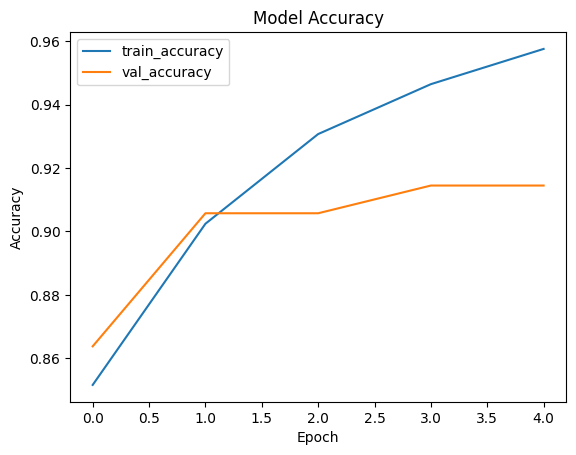

In [52]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

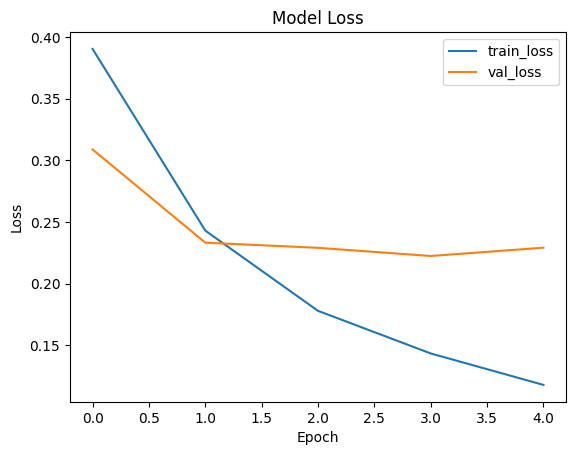

In [53]:
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


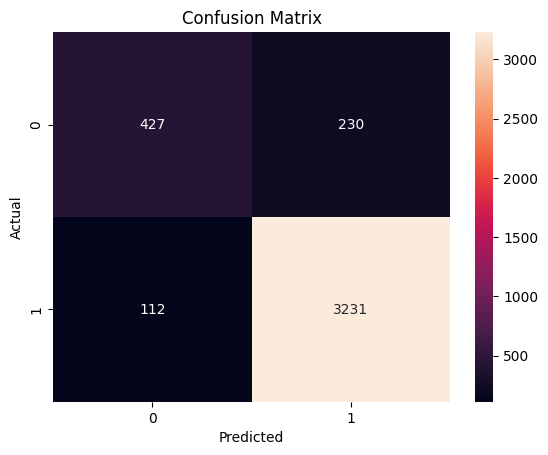

In [54]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = (model.predict(X_test) > 0.5).astype("int32")

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [55]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 58.9 MB/s eta 0:00:00


In [56]:
from gensim.models import Word2Vec

# split text into words
sentences = df["cleaned_text"].apply(lambda x: x.split())

# train Word2Vec
w2v_model = Word2Vec(
    sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4
)

In [57]:
w2v_model.wv["good"]

array([ 0.17252152,  0.16069306, -1.1661611 ,  2.154068  , -2.9212594 ,
        1.176046  ,  0.83625495,  1.1571801 , -0.34773245,  0.925685  ,
       -1.1432868 ,  2.0031867 , -0.11207433,  0.9471686 , -1.800056  ,
        0.96960455, -0.78811395, -1.7893552 ,  0.5912121 , -0.12607703,
       -0.30083144, -0.64102453, -0.5353332 ,  0.7042777 ,  0.08776301,
       -2.366948  ,  0.05305635, -0.9199456 ,  1.3304296 ,  0.55621874,
        1.4602866 , -0.8712427 ,  1.5757711 , -0.3681876 , -1.1852379 ,
        0.66312224,  0.287983  ,  0.69540244,  0.53276837, -1.0623599 ,
       -1.272126  ,  1.4748623 ,  0.3537189 , -2.6047232 ,  0.85240906,
       -0.5857752 , -0.9765028 ,  0.7895086 ,  1.0791755 ,  1.8044955 ,
       -0.90227526, -0.7806855 , -1.1780821 ,  0.1681862 ,  1.9495319 ,
        0.2535468 , -1.710301  , -1.4498484 , -1.7084595 ,  1.4716917 ,
       -1.5068951 , -1.33198   , -0.6965224 , -1.46689   , -1.8602651 ,
       -1.4450082 , -0.13974935,  0.48063645, -0.0153267 , -0.36

In [58]:
embedding_dim = 100

word_index = tokenizer.word_index

embedding_matrix = np.zeros((10000, embedding_dim))

for word, i in word_index.items():
    if i < 10000:
        if word in w2v_model.wv:
            embedding_matrix[i] = w2v_model.wv[word]

In [59]:
from tensorflow.keras.layers import Embedding

model_w2v = Sequential([
    Embedding(
        input_dim=10000,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=100,
        trainable=False  # important
    ),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [60]:
model_w2v.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [63]:
import time

start = time.time()

history_w2v = model_w2v.fit(
    X_train,
    y_train,
    epochs=5,
    validation_data=(X_test, y_test),
    batch_size=32
)

end = time.time()
print("Word2Vec training time:", round(end - start, 2), "seconds")

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8774 - loss: 0.2870 - val_accuracy: 0.8702 - val_loss: 0.3017
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8800 - loss: 0.2829 - val_accuracy: 0.8695 - val_loss: 0.3067
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8810 - loss: 0.2796 - val_accuracy: 0.8737 - val_loss: 0.2976
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8830 - loss: 0.2773 - val_accuracy: 0.8740 - val_loss: 0.2954
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8831 - loss: 0.2740 - val_accuracy: 0.8695 - val_loss: 0.2999
Word2Vec training time: 15.38 seconds


In [62]:
loss_w2v, acc_w2v = model_w2v.evaluate(X_test, y_test)
print("Word2Vec Accuracy:", acc_w2v)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8677 - loss: 0.3071
Word2Vec Accuracy: 0.8677499890327454


The Word2Vec model achieved lower accuracy compared to the Keras embedding model. This is because Word2Vec captures general word relationships but is not specifically optimized for sentiment classification, and the embeddings were not fine-tuned during training.

In [64]:
!wget http://nlp.stanford.edu/data/glove.6B.zip
!unzip glove.6B.zip

--2026-04-24 12:04:23--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2026-04-24 12:04:24--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-04-24 12:04:25--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

In [65]:
embeddings_index = {}

with open('glove.6B.100d.txt', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        vector = np.asarray(values[1:], dtype='float32')
        embeddings_index[word] = vector

In [66]:
embedding_matrix_glove = np.zeros((10000, 100))

for word, i in word_index.items():
    if i < 10000:
        if word in embeddings_index:
            embedding_matrix_glove[i] = embeddings_index[word]

In [67]:
model_glove = Sequential([
    Embedding(
        input_dim=10000,
        output_dim=100,
        weights=[embedding_matrix_glove],
        input_length=100,
        trainable=False
    ),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

In [77]:
model_glove.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [78]:

import time

start = time.time()

history_glove = model_glove.fit(
    X_train,
    y_train,
    epochs=5,
    validation_data=(X_test, y_test),
    batch_size=32
)
end = time.time()
print("GloVe training time:", round(end - start, 2), "seconds")

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8651 - loss: 0.3194 - val_accuracy: 0.8572 - val_loss: 0.3331
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8676 - loss: 0.3141 - val_accuracy: 0.8595 - val_loss: 0.3297
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8696 - loss: 0.3120 - val_accuracy: 0.8583 - val_loss: 0.3262
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8720 - loss: 0.3063 - val_accuracy: 0.8597 - val_loss: 0.3273
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8727 - loss: 0.3065 - val_accuracy: 0.8635 - val_loss: 0.3238
GloVe training time: 15.7 seconds


In [69]:
loss_glove, acc_glove = model_glove.evaluate(X_test, y_test)
print("GloVe Accuracy:", acc_glove)

125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8455 - loss: 0.3803
GloVe Accuracy: 0.8454999923706055


The GloVe model achieved the lowest accuracy among the three methods. Although it provides pre-trained word representations, it may not capture domain-specific sentiment patterns present in product reviews.

In [70]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Keras Embedding", "Word2Vec", "GloVe"],
    "Accuracy": [accuracy, acc_w2v, acc_glove]
})

results

,Model,Accuracy
0,Keras Embedding,0.91450
1,Word2Vec,0.86775
2,GloVe,0.84550


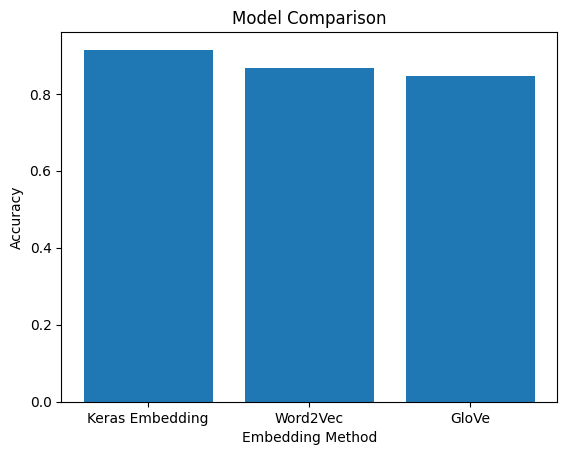

In [71]:
import matplotlib.pyplot as plt

plt.bar(results["Model"], results["Accuracy"])
plt.title("Model Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Embedding Method")
plt.show()

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


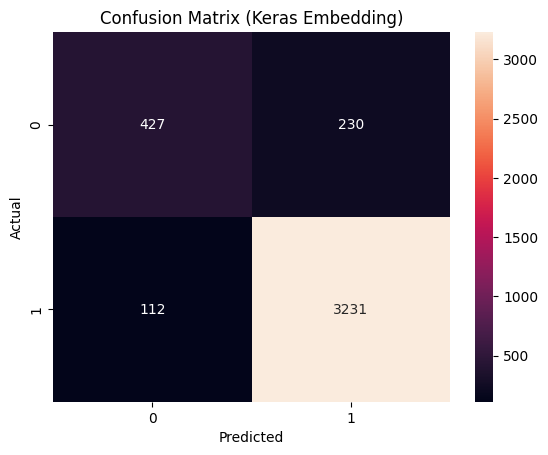

In [72]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# predictions
y_pred = (model.predict(X_test) > 0.5).astype("int32")

# confusion matrix
cm = confusion_matrix(y_test, y_pred)

# plot
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Keras Embedding)")
plt.show()

The confusion matrix shows that the model performs very well in identifying positive reviews, with a high number of true positives. However, there are some misclassifications, particularly false positives, which may be due to the imbalance in the dataset.

In [73]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.65      0.71       657
           1       0.93      0.97      0.95      3343

    accuracy                           0.91      4000
   macro avg       0.86      0.81      0.83      4000
weighted avg       0.91      0.91      0.91      4000



In [74]:
results.to_csv("model_results.csv", index=False)

In [75]:
import tensorflow as tf
tf.config.list_physical_devices('GPU')

[]

In [76]:
import platform, tensorflow as tf
print("OS:", platform.platform())
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

OS: Linux-6.6.113+-x86_64-with-glibc2.35
TensorFlow: 2.19.0
GPU: []


# Cloud vs Local Execution

This project was implemented using both Google Colab and a local machine with Python and required libraries such as TensorFlow and Gensim.

Google Colab provides a convenient cloud-based environment with pre-installed libraries and easy access through a web interface. It simplifies setup and allows rapid experimentation. However, in this project, GPU acceleration was not enabled or detected, meaning the models were trained using CPU resources.

The local environment required manual setup, including installation of dependencies and management of file paths. Despite this, it provided greater control over the system configuration.

Based on the experimental results, the local machine achieved faster training times compared to Google Colab. This is likely due to the absence of GPU acceleration in Colab and the relatively strong CPU performance of the local machine.

Overall, while Google Colab is useful for ease of use and accessibility, the local environment proved more efficient for this specific experiment when running on CPU.
